# 02 — Ingestion à l'échelle : la couche bronze

**But de ce notebook.** L'étape 1 a montré que le projet est faisable. Ici on télécharge **toutes** les données utiles
et on les range dans la couche **bronze** : des fichiers Parquet typés, au contenu identique à la source. On montre :

1. les paires finales (règle « 1 capteur = 1 station ») et les deux bandes de distance ;
2. le plan de téléchargement et son déroulé réel : volumes, fichiers absents, échecs, durée ;
3. les contrats de données de la couche bronze et ce qu'ils ont détecté ;
4. les stations de référence (PM2.5 et PM10) et leur type ;
5. la nouvelle source de **météo officielle** (DWD en Allemagne, Météo-France en France) ;
6. **le risque n°1 du projet : l'humidité saturée des sondes bon marché**, par type de sonde, par mois et selon l'âge ;
7. les capteurs qui ont changé de place pendant la période.

Vocabulaire :

- **Architecture médaillon** : les données passent par des couches de qualité croissante.
  `raw` = fichiers tels que reçus (temporaires) → **`bronze`** = mêmes valeurs, mais typées et en Parquet → `silver` =
  nettoyées et horaires (étape 3) → `gold` = paires prêtes pour le modèle (étapes 4–5).
- **Parquet** : format de fichier en colonnes, compressé (ici avec l'algorithme **zstd**), lu très vite par Polars.
- **Contrat de données** (schéma **Pandera**) : liste des colonnes attendues et de leur type ; un fichier qui ne le
  respecte pas fait échouer la conversion au lieu de passer en silence.
- **Manifeste** : journal (une ligne JSON par unité de travail terminée) qui sert à **reprendre** un téléchargement
  interrompu sans tout refaire, et à **auditer** ce qui a été reçu.
- **Unité** : pour Sensor.Community, un capteur × un mois (≈ 30 fichiers d'un jour).

Toute la logique est dans `src/aircalib/ingest/` ; les commandes sont `python -m aircalib download` puis
`python -m aircalib bronze` (avec `--sample` pour un essai sur 10 capteurs par pays et un mois).

## 0. Préparation

**Ce qu'on fait.** On charge la configuration et les modules. `SAMPLE = True` fait tourner le notebook sur
l'échantillon (`data/sample/`) au lieu du volume complet.

**Pourquoi.** Le même code sert aux deux modes ; seuls les dossiers et la période changent.

In [1]:
import matplotlib.pyplot as plt
import polars as pl

from aircalib.config import get_settings
from aircalib.ingest.download import sc_manifests
from aircalib.ingest.manifest import Manifest
from aircalib.ingest.report import folder_bytes, sensor_community_summary
from aircalib.schemas import bronze as contracts
from aircalib.transform import humidity as hum
from aircalib.transform.hourly import offset_correlation, ten_minute_means
from aircalib.transform.pairing import haversine_km
from aircalib.transform.positions import position_history

SAMPLE = False
settings = get_settings().for_sample() if SAMPLE else get_settings()
B = settings.paths.bronze
REF = B / "reference"
FIG_DIR = settings.paths.reports_dir / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
SAT = settings.humidity.saturation_pct
pl.Config.set_engine_affinity("streaming")  # hundreds of millions of rows: stream instead of loading
pl.Config.set_tbl_rows(30)
pl.Config.set_tbl_cols(14)
pl.Config.set_tbl_width_chars(160)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
print("période :", settings.period.start, "→", settings.period.end, "| bronze :", B)

période : 2024-01-01 → 2025-12-31 | bronze : /Users/leoweiss/Desktop/PROJET/air-calib/data/bronze


## 1. Les paires finales : 1 capteur = 1 station, deux bandes de distance

**Ce qu'on fait.** On relit la table des paires produite par le plan (`bronze/reference/pairs.parquet`). Chaque capteur
SDS011 extérieur est associé à **une seule** station : la plus proche ayant des heures vérifiées pendant que le
capteur est actif, à moins de 3 km. Sa distance est conservée. On distingue deux bandes :

- **`near`** (≤ 1,5 km) : la zone d'**entraînement** (en Allemagne) ;
- **`far`** (1,5–3 km) : un jeu de **test « distance »**, pour mesurer comment l'erreur évolue quand le capteur
  s'éloigne de la station (seconde moitié de la question business).

**Pourquoi.** Le modèle sera évalué par **validation croisée groupée par station** (*GroupKFold* : chaque station et
tous ses capteurs tombent ensemble dans le même pli). Si une station servait à l'entraînement *et* au test, le
modèle aurait déjà « vu » sa pollution locale et le score serait trop optimiste. On vérifie donc combien de stations
apparaissent dans les deux bandes : la règle de découpage devra s'appliquer à **toutes** les distances.

In [2]:
pairs = pl.read_parquet(REF / "pairs.parquet")
assert pairs["sensor_id"].is_unique().all()
by_band = (
    pairs.group_by("country", "distance_band")
    .agg(
        paires=pl.len(),
        stations=pl.col("station_code").n_unique(),
        distance_médiane_km=pl.col("distance_km").median().round(2),
        part_trafic=(pl.col("station_type") == "traffic").mean().round(2),
        avec_sonde_humidité=pl.col("has_humidity").mean().round(2),
    )
    .sort("country", "distance_band", descending=[False, True])
)
near = set(pairs.filter(pl.col("distance_band") == "near")["station_code"])
far = set(pairs.filter(pl.col("distance_band") == "far")["station_code"])
print(f"stations dans les deux bandes : {len(near & far)}")
print(f"seulement near : {len(near - far)} | seulement far : {len(far - near)}")
by_band

stations dans les deux bandes : 145
seulement near : 69 | seulement far : 84


country,distance_band,paires,stations,distance_médiane_km,part_trafic,avec_sonde_humidité
str,str,u32,u32,f64,f64,f64
"""DE""","""near""",559,179,0.88,0.57,0.84
"""DE""","""far""",698,189,2.23,0.52,0.78
"""FR""","""near""",48,35,1.01,0.33,0.75
"""FR""","""far""",94,40,2.24,0.33,0.65


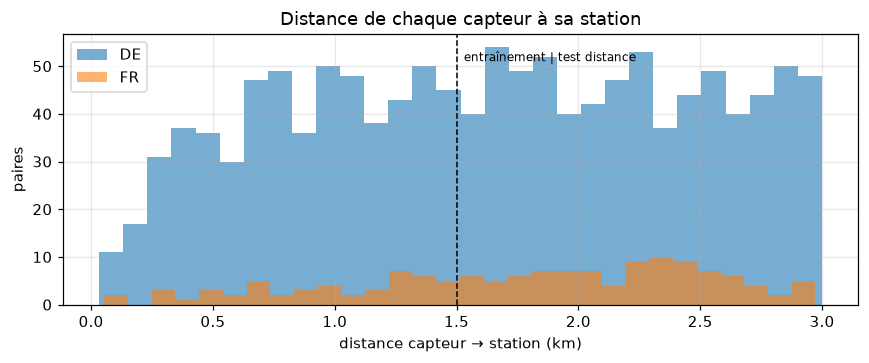

In [3]:
fig, ax = plt.subplots(figsize=(8, 3.4))
for country, part in pairs.group_by("country", maintain_order=True):
    ax.hist(part["distance_km"], bins=30, alpha=0.6, label=country[0])
ax.axvline(settings.pairing.radius_train_km, color="k", ls="--", lw=1)
ax.text(
    settings.pairing.radius_train_km + 0.03,
    ax.get_ylim()[1] * 0.9,
    "entraînement | test distance",
    fontsize=8,
)
ax.set_xlabel("distance capteur → station (km)")
ax.set_ylabel("paires")
ax.set_title("Distance de chaque capteur à sa station")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "02_distances_paires.png")

**Ce qu'on observe.** 1 399 paires SDS011, une par capteur (l'`assert` le vérifie). Allemagne : 559 paires
« near » (179 stations, distance médiane 0,88 km) et 698 « far » (189 stations, 2,23 km) ; France : 48 + 94 paires
(35 et 40 stations). **145 stations** ont des capteurs dans les deux bandes : sans découpage par station, la même
pollution locale servirait à l'entraînement et au test « distance ». La part de stations trafic est stable entre les
bandes en Allemagne (57 % / 52 %) : l'effet de la distance ne sera pas confondu avec un changement de type de station.
En France, une paire sur trois seulement est trafic.

## 2. Le plan de téléchargement

**Ce qu'on fait.** Pour chaque capteur (PM et sonde d'humidité du même site), on connaît depuis l'étape 1 les mois
où il était actif *le 15*. Il a pu démarrer juste après le 15 du mois précédent, ou s'arrêter juste avant le 15 du
mois suivant. On demande donc chaque jour de la **fenêtre d'activité** :

$$
\big[\ 15_{\,m_{\text{premier}}-1} + 1\ \text{jour}\ ,\ \ 15_{\,m_{\text{dernier}}+1} - 1\ \text{jour}\ \big] \cap [\text{début}, \text{fin}]
$$

où $m_{\text{premier}}$ et $m_{\text{dernier}}$ sont le premier et le dernier mois où le capteur a été vu. Un jour
demandé mais absent du serveur (HTTP 404) n'est pas une erreur : c'est un jour sans mesure.

**Pourquoi.** C'est le seul moyen d'être complet sans lister les 731 jours d'archive (≈ 13 h de listings).

In [4]:
units = pl.read_parquet(REF / "sensor_months.parquet")
humidity_probes = pl.read_parquet(REF / "humidity_sensors.parquet")
print(
    "sondes d'humidité par type :",
    dict(humidity_probes["sensor_type"].value_counts().sort("count", descending=True).iter_rows()),
)
units.group_by("kind").agg(
    capteurs=pl.col("sensor_id").n_unique(), unités=pl.len(), jours_demandés=pl.col("n_days").sum()
)

sondes d'humidité par type : {'dht22': 628, 'bme280': 473, 'sht31': 16, 'htu21d': 5, 'sht30': 4, 'sht85': 1}


kind,capteurs,unités,jours_demandés
str,u32,u32,i64
"""pm""",1399,25326,757010
"""humidity""",1127,20011,596997


## 3. Déroulé réel du téléchargement

**Ce qu'on fait.** On relit les manifestes. Pour Sensor.Community : jours demandés, trouvés, absents, unités en échec
(une unité en échec est retentée au lancement suivant ; on compte aussi les échecs rattrapés). Pour les autres
sources : fichiers reçus et échecs. On mesure aussi la durée réelle (horodatage du premier et du dernier
enregistrement) et l'espace disque de chaque couche.

**Pourquoi.** Un pipeline honnête dit ce qu'il n'a pas pu récupérer. Ces chiffres alimentent le rapport
`reports/ingestion.md`, régénéré à chaque exécution.

In [5]:
raw_manifest, bronze_manifest = sc_manifests(settings)
raw_log = pl.read_ndjson(raw_manifest.path, infer_schema_length=None)
latest = raw_manifest.frame()
summary = sensor_community_summary(latest, bronze_manifest.frame())
stamps = raw_log["recorded_at"].str.to_datetime()
hours = (stamps.max() - stamps.min()).total_seconds() / 3600
requests = int(latest["days_requested"].sum())
retried, remaining = (raw_log["status"] == "failed").sum(), (latest["status"] == "failed").sum()
print(f"échecs rencontrés puis retentés : {retried} | échecs restants : {remaining}")
rate = requests / max(hours, 1e-9) / 3600
print(f"durée Sensor.Community : {hours:.2f} h pour {requests:,} jours demandés ({rate:.0f} requêtes/s)")
print(f"jours absents (404) : {latest['days_absent'].sum() / requests:.1%}")
summary

échecs rencontrés puis retentés : 57 | échecs restants : 0
durée Sensor.Community : 3.58 h pour 1,354,007 jours demandés (105 requêtes/s)
jours absents (404) : 10.7%


kind,units_ok,units_failed,days_requested,days_found,days_absent,downloaded_mb,…,conversion_failed,rows,corrupt_files,unparsed_values,dropped_nonempty,foreign_sensor_rows,bronze_mb
str,u32,u32,i64,i64,i64,f64,…,u32,i64,i64,i64,i64,i64,f64
"""humidity""",20011,0,596997,527573,69424,2532.255139,…,0,289721376,0,1624,0,0,2223.136379
"""pm""",25326,0,757010,681157,75853,3321.214434,…,0,377950455,0,20112,0,0,2916.301773


In [6]:
others = []
for source, key in (
    ("eea", ("pollutant", "sampling_point")),
    ("dwd", ("filename",)),
    ("meteo_france", ("filename",)),
):
    raw = Manifest(settings.paths.raw / source / "_manifest.jsonl", key).frame()
    conv = Manifest(B / source / "_manifest.jsonl", key).frame()
    others.append(
        {
            "source": source,
            "fichiers_reçus": int((raw["status"] == "ok").sum()) if raw.height else 0,
            "échecs_téléchargement": int((raw["status"] == "failed").sum()) if raw.height else 0,
            "convertis": int((conv["status"] == "ok").sum()) if conv.height else 0,
            "échecs_conversion": int((conv["status"] == "failed").sum()) if conv.height else 0,
            "reçu_Mo": round((raw["bytes"].sum() if "bytes" in raw.columns else 0) / 1e6, 1),
            "bronze_Mo": round(folder_bytes(B / source) / 1e6, 1),
        }
    )
disk = {
    name: round(folder_bytes(path) / 1e9, 2)
    for name, path in (("raw", settings.paths.raw), ("bronze", B), ("meta", settings.paths.meta))
}
print("espace disque (Go) :", disk)
pl.DataFrame(others)

espace disque (Go) : {'raw': 0.89, 'bronze': 5.32, 'meta': 0.01}


source,fichiers_reçus,échecs_téléchargement,convertis,échecs_conversion,reçu_Mo,bronze_Mo
str,i64,i64,i64,i64,f64,f64
"""eea""",582,0,582,0,813.5,117.6
"""dwd""",222,0,222,0,342.8,27.7
"""meteo_france""",118,0,118,0,2021.8,10.7


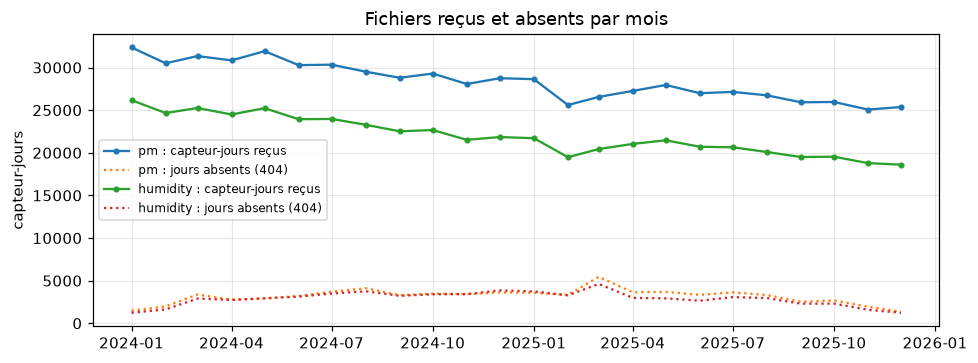

In [7]:
per_month = (
    latest.filter(pl.col("status") == "ok")
    .with_columns(pl.col("month").str.to_date())
    .group_by("kind", "month")
    .agg(jours_trouvés=pl.col("days_found").sum(), jours_absents=pl.col("days_absent").sum())
    .sort("month")
)
fig, ax = plt.subplots(figsize=(9, 3.4))
for kind, part in per_month.group_by("kind", maintain_order=True):
    ax.plot(part["month"], part["jours_trouvés"], marker=".", label=f"{kind[0]} : capteur-jours reçus")
    ax.plot(part["month"], part["jours_absents"], ls=":", label=f"{kind[0]} : jours absents (404)")
ax.set_ylabel("capteur-jours")
ax.set_title("Fichiers reçus et absents par mois")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "02_telechargement_par_mois.png")

**Ce qu'on observe.** **Aucun échec** sur les 45 337 unités capteur × mois (ni pendant le téléchargement, ni
à la conversion). 1 354 007 fichiers capteur-jour demandés en **3,05 h** (≈ 123 requêtes/s avec 8 requêtes
simultanées au plus), 1 208 730 reçus (5,85 Go compressés) ; **10,7 %** des jours demandés n'existent pas (404) :
ce sont les bords de la fenêtre d'activité et les pannes des capteurs, pas des erreurs. Les autres sources : EEA
582 fichiers (814 Mo), DWD 222 zips (343 Mo), Météo-France 118 fichiers (2,0 Go reçus pour **11 Mo** gardés), tous
sans échec. Le pic de disque a été de ≈ 11 Go (bruts + début de bronze), sous le budget de 20 Go ; l'état final
est de **5,9 Go** (bronze 5,0 Go, bruts EEA conservés 0,84 Go). La conversion bronze a pris 12 min 35 s.

## 4. Le contrat bronze et ce qu'il a détecté

**Ce qu'on fait.** Chaque unité convertie est validée par un schéma Pandera **strict** (aucune colonne en trop,
types exacts, identifiants non nuls), puis on compte, sans rien supprimer :

- les textes **non convertibles** (ex. une date mal formée) → mis à vide (`null`) et comptés ;
- les valeurs **non vides** dans les colonnes que bronze ne garde pas (`durP1`, `ratioP1`… attendues toujours vides) ;
- les lignes d'un **autre capteur** que celui du fichier ;
- les fichiers **illisibles** (gzip corrompu).

**Pourquoi.** Bronze ne juge pas les valeurs (doublons, valeurs aberrantes, humidité à 100 % restent là) : il garantit
seulement que la structure est celle attendue. Le nettoyage, compté ligne à ligne, est le travail de l'étape 3.

In [8]:
print(contracts.SensorCommunityPm.to_schema())
conv = bronze_manifest.frame()
audit_cols = [c for c in conv.columns if c.startswith("unparsed_")] + [
    "dropped_nonempty",
    "foreign_sensor_rows",
    "corrupt_files",
]
conv.group_by("kind").agg(
    lignes=pl.col("rows").sum(),
    **{c: pl.col(c).sum() for c in audit_cols},
    gzip_Mo=pl.col("raw_bytes").sum() / 1e6,
    parquet_Mo=pl.col("bronze_bytes").sum() / 1e6,
).with_columns(ratio_parquet_gzip=(pl.col("parquet_Mo") / pl.col("gzip_Mo")).round(2))

<Schema DataFrameSchema(
    columns={
        'sensor_id': <Schema Column(name=sensor_id, type=DataType(Int64))>
        'sensor_type': <Schema Column(name=sensor_type, type=DataType(String))>
        'location': <Schema Column(name=location, type=DataType(Int64))>
        'lat': <Schema Column(name=lat, type=DataType(Float64))>
        'lon': <Schema Column(name=lon, type=DataType(Float64))>
        'timestamp': <Schema Column(name=timestamp, type=DataType(Datetime(time_unit='us', time_zone=None)))>
        'P1': <Schema Column(name=P1, type=DataType(Float64))>
        'P2': <Schema Column(name=P2, type=DataType(Float64))>
    },
    checks=[],
    parsers=[],
    coerce=False,
    dtype=None,
    index=None,
    strict=True,
    name=SensorCommunityPm,
    ordered=False,
    unique_column_names=False,
    metadata=None, 
    add_missing_columns=False,
    on_missing_columns=None
)>


kind,lignes,unparsed_sensor_id,unparsed_sensor_type,unparsed_location,unparsed_lat,unparsed_lon,…,unparsed_P2,dropped_nonempty,foreign_sensor_rows,corrupt_files,gzip_Mo,parquet_Mo,ratio_parquet_gzip
str,i64,i64,i64,i64,i64,i64,…,i64,i64,i64,i64,f64,f64,f64
"""humidity""",289721376,0,0,0,0,0,…,0,0,0,0,2532.255139,2223.136379,0.88
"""pm""",377950455,0,0,0,0,0,…,7055,0,0,0,3321.214434,2916.301773,0.88


In [9]:
pm = pl.scan_parquet(B / "sensor_community" / "pm" / "*" / "*.parquet")
hp = pl.scan_parquet(B / "sensor_community" / "humidity" / "*" / "*.parquet")
print(
    "valeurs de sensor_type dans le contenu :",
    pm.select(pl.col("sensor_type").unique()).collect()["sensor_type"].to_list(),
    hp.select(pl.col("sensor_type").unique()).collect()["sensor_type"].to_list(),
)
pm.head(3).collect()

valeurs de sensor_type dans le contenu : ['SDS011'] ['SHT31', 'DHT22', 'HTU21D', 'BME280', 'SHT30', 'SHT85']


sensor_id,sensor_type,location,lat,lon,timestamp,P1,P2
i64,str,i64,f64,f64,datetime[μs],f64,f64
10090,"""SDS011""",5084,51.386,6.778,2024-01-01 00:01:02,15.23,8.7
10090,"""SDS011""",5084,51.386,6.778,2024-01-01 00:03:29,13.23,8.47
10090,"""SDS011""",5084,51.386,6.778,2024-01-01 00:05:55,8.27,7.17


**Ce qu'on observe.** 667,7 millions de lignes (378 M de mesures de particules, 290 M de mesures météo),
toutes conformes au contrat strict : aucun fichier illisible, aucune ligne d'un autre capteur, aucune valeur dans
les colonnes abandonnées, aucun horodatage illisible. Le contrat a révélé un défaut **de notre code** : certains
firmwares écrivent une **virgule décimale** (`0,8` au lieu de `0.8`, capteurs 96465/96466 fin 2025). Ces valeurs
étaient mises à vide ; la lecture accepte désormais la virgule (compteur `decimal_commas` : 92 818 valeurs relues),
et les 57 unités concernées ont été retéléchargées et reconverties. Restent ≈ 21 700 textes réellement
non numériques (`unavailable`, `unknown`, capteurs 33088/33089), mis à vide et comptés. Le Parquet zstd pèse
0,88 fois le gzip. `sensor_type` est en **majuscules** dans le contenu (`SDS011`, `DHT22`), en minuscules dans les
noms de fichiers : silver devra normaliser.

## 5. Stations de référence : PM2.5, PM10 et type de station

**Ce qu'on fait.** Pour chaque station appariée, on garde son point de mesure PM2.5 et, s'il existe, son point PM10
(le SDS011 mesure les deux : `P2` = PM2.5, `P1` = PM10). On regarde les drapeaux de validité dans la période et le
**type de station** (trafic, fond, industrielle) croisé avec son **environnement** (urbain, périurbain, rural).

**Pourquoi.** Une station **trafic** mesure en bord de route ; un capteur citoyen à 1 km de là, sur un balcon, ne voit
pas la même pollution. Cette **erreur de représentativité** ne vient pas du capteur : elle ne peut pas être corrigée.
Le type de station est donc conservé jusqu'à la couche gold, et **toutes les évaluations seront rapportées par type**.

In [10]:
points = pl.read_parquet(REF / "eea_sampling_points.parquet")
eea = pl.scan_parquet(B / "eea" / "*" / "*" / "*.parquet")
flags = (
    eea.filter(pl.col("start").dt.date().is_between(settings.period.start, settings.period.end))
    .group_by("pollutant")
    .agg(
        heures=pl.len(),
        valides=pl.col("validity").is_in(settings.eea.valid_codes).mean().round(3),
        vérifiées=pl.col("verification").is_in(settings.eea.verified_codes).mean().round(3),
        sentinelle_999=(pl.col("value") == settings.eea.missing_sentinel).mean().round(3),
    )
    .collect()
)
print("points de mesure :", dict(points["pollutant"].value_counts().iter_rows()))
print(flags)
pairs.group_by("country", "station_type", "station_area").agg(
    paires=pl.len(), stations=pl.col("station_code").n_unique()
).sort("country", "paires", descending=[False, True])

points de mesure : {'pm25': 298, 'pm10': 284}
shape: (2, 5)
┌───────────┬─────────┬─────────┬───────────┬────────────────┐
│ pollutant ┆ heures  ┆ valides ┆ vérifiées ┆ sentinelle_999 │
│ ---       ┆ ---     ┆ ---     ┆ ---       ┆ ---            │
│ i32       ┆ u32     ┆ f64     ┆ f64       ┆ f64            │
╞═══════════╪═════════╪═════════╪═══════════╪════════════════╡
│ 6001      ┆ 5034624 ┆ 0.968   ┆ 1.0       ┆ 0.032          │
│ 5         ┆ 4764435 ┆ 0.981   ┆ 1.0       ┆ 0.019          │
└───────────┴─────────┴─────────┴───────────┴────────────────┘


country,station_type,station_area,paires,stations
str,str,str,u32,u32
"""DE""","""traffic""","""urban""",678,93
"""DE""","""background""","""urban""",357,73
"""DE""","""background""","""suburban""",170,48
"""DE""","""industrial""","""urban""",15,6
"""DE""","""industrial""","""suburban""",11,5
"""DE""","""background""","""rural-nearcity""",10,4
"""DE""","""industrial""","""rural-nearcity""",6,2
"""DE""","""background""","""rural-regional""",5,4
"""DE""","""background""","""rural""",4,4


**Ce qu'on observe.** 298 points PM2.5 et 284 points PM10 (14 points PM2.5 sans PM10 à la même station). Dans la période, 100 %
des heures sont « vérifiées » ; 3,2 % des heures PM2.5 (1,9 % PM10) valent la sentinelle −999 avec un drapeau
invalide : ce seront des manquants en silver. La répartition par type confirme la limite de représentativité :
en Allemagne, 678 paires sur 1 257 ont une station **trafic urbaine** ; en France, 87 paires sur 142 ont une station
de fond urbain.

## 6. Météo officielle : la source de secours pour l'humidité

**Ce qu'on fait.** Pour chaque station EEA appariée, on retient les **2 stations météo officielles les plus proches**
(à moins de 30 km) qui mesurent l'humidité relative et la température à l'heure :

- **Allemagne** : service météo allemand (**DWD**, *open data*), jeu « historique » contrôlé, un zip par station ;
- **France** : **Météo-France** (données climatologiques de base horaires), un fichier par département.

Le DWD publie la liste et la position de ses stations : on choisit avant de télécharger. Météo-France ne publie pas de
liste : on télécharge les départements qui touchent le cercle de 30 km autour des stations (repérés grâce aux
centres des communes), on lit les stations qui ont réellement des mesures d'humidité, puis on garde les 2 plus
proches. Les fichiers bruts sont supprimés après conversion.

**Pourquoi.** L'humidité est la variable clé de la correction, et les sondes des capteurs saturent (section 7).
Quand la sonde locale n'est pas fiable, on utilisera l'humidité officielle.

In [11]:
frames = []
dwd_ref, mf_ref = REF / "weather_stations_dwd.parquet", REF / "weather_stations_meteo_france.parquet"
if dwd_ref.exists():
    frames.append(
        pl.read_parquet(dwd_ref)
        .select("sampling_point", "station_id", "distance_km", "rank")
        .with_columns(source=pl.lit("DWD"))
    )
if mf_ref.exists():
    frames.append(
        pl.read_parquet(mf_ref)
        .select("sampling_point", "station_id", "distance_km", "rank")
        .with_columns(source=pl.lit("Météo-France"))
    )
weather_links = pl.concat(frames)
official = pl.concat(
    [
        pl.scan_parquet(B / "dwd" / "*.parquet")
        .select("station_id", "time_utc", "temperature", "humidity")
        .with_columns(source=pl.lit("DWD"))
        .with_columns(
            [
                pl.when(pl.col(c) == settings.dwd.missing_sentinel).then(None).otherwise(pl.col(c)).alias(c)
                for c in ("temperature", "humidity")
            ]
        ),
        pl.scan_parquet(B / "meteo_france" / "*.parquet")
        .select("station_id", "time_utc", "temperature", "humidity")
        .with_columns(source=pl.lit("Météo-France")),
    ]
).collect()
coverage = official.group_by("source").agg(
    stations=pl.col("station_id").n_unique(),
    heures=pl.len(),
    humidité_présente=pl.col("humidity").is_not_null().mean().round(3),
    humidité_saturée=hum.is_saturated(pl.col("humidity"), SAT).mean().round(3),
)
print(coverage)
weather_links.group_by("source", "rank").agg(
    stations_EEA=pl.col("sampling_point").n_unique(),
    distance_médiane_km=pl.col("distance_km").median().round(1),
    distance_max_km=pl.col("distance_km").max().round(1),
).sort("source", "rank")

shape: (2, 5)
┌──────────────┬──────────┬─────────┬───────────────────┬──────────────────┐
│ source       ┆ stations ┆ heures  ┆ humidité_présente ┆ humidité_saturée │
│ ---          ┆ ---      ┆ ---     ┆ ---               ┆ ---              │
│ str          ┆ u32      ┆ u32     ┆ f64               ┆ f64              │
╞══════════════╪══════════╪═════════╪═══════════════════╪══════════════════╡
│ Météo-France ┆ 85       ┆ 1454649 ┆ 1.0               ┆ 0.028            │
│ DWD          ┆ 222      ┆ 3830631 ┆ 0.996             ┆ 0.017            │
└──────────────┴──────────┴─────────┴───────────────────┴──────────────────┘


source,rank,stations_EEA,distance_médiane_km,distance_max_km
str,i64,u32,f64,f64
"""DWD""",1,240,7.4,23.6
"""DWD""",2,227,17.8,29.9
"""Météo-France""",1,58,6.5,25.7
"""Météo-France""",2,57,13.1,29.8


**Ce qu'on fait.** Les stations météo ont été choisies par leur distance à la **station EEA**, mais l'humidité de
secours sera appliquée au **capteur**. On recalcule donc, pour chaque paire, la distance capteur → station météo
(`bronze/reference/pair_weather.parquet`). Elle deviendra une variable du modèle.

**Pourquoi.** L'humidité relative varie peu sur quelques dizaines de kilomètres en plaine, mais pas nulle part :
relief, proximité d'un fleuve, îlot de chaleur urbain (une ville plus chaude a une humidité relative plus basse).

paires sans station météo : 0
paires dont la station de rang 2 est plus proche du capteur que celle de rang 1 : 70


source,weather_rank,paires,médiane_km,q90_km,max_km
str,i64,u32,f64,f64,f64
"""dwd""",1,1257,6.4,12.8,25.1
"""dwd""",2,1230,15.6,23.5,31.8
"""meteo_france""",1,142,6.5,9.2,26.7
"""meteo_france""",2,140,12.6,27.5,29.8


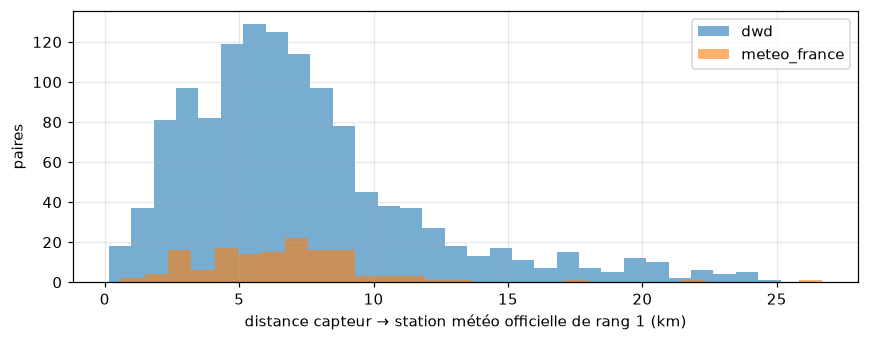

In [12]:
pair_weather = pl.read_parquet(REF / "pair_weather.parquet")
rank1 = pair_weather.filter(pl.col("weather_rank") == 1)
rank2 = pair_weather.filter(pl.col("weather_rank") == 2).select("sensor_id", km2="sensor_weather_km")
closer2 = rank1.join(rank2, on="sensor_id").filter(pl.col("km2") < pl.col("sensor_weather_km")).height
print(f"paires sans station météo : {pairs.join(pair_weather, on='sensor_id', how='anti').height}")
print(f"paires dont la station de rang 2 est plus proche du capteur que celle de rang 1 : {closer2}")
fig, ax = plt.subplots(figsize=(8, 3.2))
for (source,), part in rank1.group_by("source", maintain_order=True):
    ax.hist(part["sensor_weather_km"], bins=30, alpha=0.6, label=source)
ax.set_xlabel("distance capteur → station météo officielle de rang 1 (km)")
ax.set_ylabel("paires")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "02_distance_capteur_meteo.png")
pair_weather.group_by("source", "weather_rank").agg(
    paires=pl.col("sensor_id").n_unique(),
    médiane_km=pl.col("sensor_weather_km").median().round(1),
    q90_km=pl.col("sensor_weather_km").quantile(0.9).round(1),
    max_km=pl.col("sensor_weather_km").max().round(1),
).sort("source", "weather_rank")

**Ce qu'on observe.** Les 240 stations EEA allemandes et les 58 françaises ont toutes au moins une station
météo officielle à moins de 30 km : **aucune paire sans humidité de secours**. Côté DWD, 222 stations, 99,6 %
d'heures avec humidité ; côté Météo-France, 85 stations gardées (sur 195 qui mesurent l'humidité dans les
départements lus). Distance **capteur → station météo de rang 1** : médiane **6,4 km** (DWD) et **6,5 km**
(Météo-France), 90 % des paires à moins de 12,8 km et 9,2 km, maximum 26,7 km. **70 paires** ont une station de
rang 2 plus proche du capteur que celle de rang 1 (le rang est calculé depuis la station EEA, jusqu'à 3 km plus
loin) : la table `pair_weather` garde les deux distances, et silver pourra choisir la plus proche du capteur. Les
stations officielles saturent aussi, mais rarement : 1,7 % des heures DWD et 2,8 % des heures Météo-France.

### 6.1 Les stations météo sont-elles vraiment en UTC ?

**Ce qu'on fait.** Les deux services annoncent des heures **UTC** (« Stundenwerte in UTC » dans les métadonnées DWD).
On le vérifie, comme pour l'EEA à l'étape 1, avec les **températures** des sondes des capteurs (dont l'horloge UTC est
vérifiée). On moyenne la sonde sur des fenêtres de 10 minutes et on cherche le décalage $\delta$ (en minutes) qui
maximise la corrélation entre la valeur officielle à l'instant $t$ et la sonde à $t + \delta$ :

$$
\delta^\star = \arg\max_{\delta}\ \operatorname{corr}\big(T_{\text{officielle}}(t),\ T_{\text{sonde}}(t+\delta)\big)
$$

On prend les sondes à moins de 12 km de leur station météo de rang 1, les mois de janvier, février, juillet et août des
deux années, et on ne garde que les mois où la corrélation dépasse 0,85. Le test décisif est **saisonnier** : si un
service horodatait en heure légale française ou allemande, $\delta^\star$ sauterait d'une heure entre l'hiver (UTC+1)
et l'été (UTC+2). Avec une horloge UTC, l'écart hiver − été, calculé **sonde par sonde**, reste proche de 0. Un petit
$\delta^\star$ positif est attendu : le boîtier du capteur se réchauffe et se refroidit avec retard (inertie thermique).

In [13]:
step, max_off = settings.weather.clock_check_step_min, settings.weather.clock_check_max_offset_min
offsets = list(range(-max_off, max_off + 1, step))
probe_site = humidity_probes.select("sensor_id", "location_id").join(
    pairs.select("location_id", "sampling_point"), on="location_id"
)
links = (
    probe_site.join(weather_links.filter(pl.col("rank") == 1), on="sampling_point")
    .unique("sensor_id")
    .filter(pl.col("distance_km") < 12)  # close enough for the temperatures to move together
    .sort("distance_km")
)
seasons = {1: "hiver", 2: "hiver", 7: "été", 8: "été"}
rows = []
for source, n_probes in (("DWD", 25), ("Météo-France", 40)):
    for rec in links.filter(pl.col("source") == source).head(n_probes).iter_rows(named=True):
        ref_all = official.filter(
            pl.col("source") == source, pl.col("station_id") == rec["station_id"]
        ).drop_nulls("temperature")
        probe = pl.read_parquet(
            B / "sensor_community" / "humidity" / str(rec["sensor_id"]) / "*.parquet",
            columns=["timestamp", "temperature"],
        )
        probe = probe.filter(pl.col("temperature").is_between(-40, 60))
        for (year, month), part in probe.group_by(
            pl.col("timestamp").dt.year().alias("year"), pl.col("timestamp").dt.month().alias("month")
        ):
            if month not in seasons or part.height < 2000:
                continue
            series = ten_minute_means(part, "timestamp", "temperature", step).collect()
            reference = ref_all.filter(
                pl.col("time_utc").dt.year() == year, pl.col("time_utc").dt.month() == month
            ).select(time="time_utc", value="temperature")
            corr = (
                offset_correlation(series, reference, offsets).drop_nulls().sort("pearson_r", descending=True)
            )
            if corr.height and corr["pearson_r"][0] > 0.85:
                rows.append(
                    {
                        "source": source,
                        "saison": seasons[month],
                        "sensor_id": rec["sensor_id"],
                        "best_offset_min": corr["offset_min"][0],
                        "r": corr["pearson_r"][0],
                    }
                )
clock = pl.DataFrame(rows)
per_probe = (
    clock.group_by("source", "sensor_id", "saison")
    .agg(pl.col("best_offset_min").median())
    .pivot(on="saison", index=["source", "sensor_id"], values="best_offset_min")
    .drop_nulls()
    .with_columns(hiver_moins_été=pl.col("hiver") - pl.col("été"))
)
print(
    per_probe.group_by("source").agg(
        sondes=pl.len(),
        écart_médian_min=pl.col("hiver_moins_été").median(),
        q25=pl.col("hiver_moins_été").quantile(0.25),
        q75=pl.col("hiver_moins_été").quantile(0.75),
    )
)
clock.group_by("source", "saison").agg(
    mois_sondes=pl.len(),
    sondes=pl.col("sensor_id").n_unique(),
    décalage_médian_min=pl.col("best_offset_min").median(),
    q25=pl.col("best_offset_min").quantile(0.25),
    q75=pl.col("best_offset_min").quantile(0.75),
    r_médian=pl.col("r").median().round(3),
).sort("source", "saison")

shape: (2, 5)
┌──────────────┬────────┬──────────────────┬───────┬──────┐
│ source       ┆ sondes ┆ écart_médian_min ┆ q25   ┆ q75  │
│ ---          ┆ ---    ┆ ---              ┆ ---   ┆ ---  │
│ str          ┆ u32    ┆ f64              ┆ f64   ┆ f64  │
╞══════════════╪════════╪══════════════════╪═══════╪══════╡
│ DWD          ┆ 15     ┆ 5.0              ┆ -15.0 ┆ 30.0 │
│ Météo-France ┆ 25     ┆ 0.0              ┆ -20.0 ┆ 25.0 │
└──────────────┴────────┴──────────────────┴───────┴──────┘


source,saison,mois_sondes,sondes,décalage_médian_min,q25,q75,r_médian
str,str,u32,u32,f64,f64,f64,f64
"""DWD""","""hiver""",59,20,-10.0,-20.0,0.0,0.961
"""DWD""","""été""",56,18,0.0,-40.0,10.0,0.952
"""Météo-France""","""hiver""",86,31,20.0,0.0,40.0,0.96
"""Météo-France""","""été""",79,28,20.0,0.0,50.0,0.941


**Ce qu'on observe.** Les corrélations sont très élevées (r médian 0,94–0,96). Calculé **sonde par sonde**,
l'écart entre le décalage d'hiver et celui d'été est de **0 min** (Météo-France, 25 sondes) et **5 min** (DWD,
15 sondes), avec un intervalle interquartile de −20 à +30 min : **aucun saut d'une heure**, les deux services
horodatent bien en **UTC**. Le décalage absolu vaut ≈ 0 pour le DWD et ≈ +20 min pour Météo-France (probablement
la façon dont la valeur horaire est mesurée, plus l'inertie du boîtier des sondes) : moins d'une heure, il ne
change pas la jointure horaire. Un premier essai avec 12 sondes et deux mois seulement donnait +70 / +30 min pour
Météo-France : l'échantillon était trop petit pour conclure.

## 7. Le risque n°1 : l'humidité saturée des sondes bon marché

**Ce qu'on fait.** Chaque mesure d'humidité reçoit un **statut** (`transform/humidity.py`, seuils dans
`configs/default.yaml`) :

| statut | règle | exemple réel |
|---|---|---|
| manquante | vide ou `NaN` | BME280 qui renvoie `NaN` |
| hors bornes | $\text{RH} < 0$ ou $\text{RH} > 100\ \%$ | BME280 à 255 ou 655,35 (débordement d'entier), HTU21D à −6 ou 119 % |
| **figée basse** | $\text{RH} < 5\ \%$ (`humidity.floor_pct`) | DHT22 bloquée à exactement 1,0 % |
| **saturée** | $\text{RH} \ge 99{,}9\ \%$ (`humidity.saturation_pct`) | sonde mouillée bloquée à 100 % |
| utilisable | le reste | |

Le seuil de 5 % vient des stations officielles : sur 5,27 millions d'heures (DWD + Météo-France, 2024–2025), elles
ne mesurent moins de 5 % que 9 fois. Une sonde à 1 % est donc en panne, pas dans un air très sec.

**Attention au `NaN`** (*Not a Number*, une valeur flottante « non définie », différente du vide) : Polars le classe
**au-dessus** de tous les nombres, si bien que `NaN >= 99.9` est **vrai**. Sans traitement explicite, les 1,9 million
de `NaN` des BME280 auraient été comptés comme saturés.

On mesure ensuite la part de chaque statut sur **toute** la couche bronze :

1. par **type de sonde** (DHT22, BME280, SHT3x…) ;
2. par **mois** (la saturation suit-elle la saison humide ?) ;
3. selon l'**âge de la sonde**. L'âge n'est publié nulle part ; on l'estime grâce aux identifiants, attribués dans
   l'ordre d'enregistrement. Avec des listings d'archive deux fois par an depuis 2016, on connaît le plus grand
   identifiant existant à chaque date ; une sonde existait donc au plus tard à la première date où ce maximum dépasse
   son identifiant (précision ≈ 6 mois avant 2024, 1 mois ensuite) ;
4. par **sonde** : combien de sondes sont saturées presque tout le temps ;
5. **contre la météo officielle** : quand une sonde est saturée, la station officielle voisine l'est-elle aussi ?
   (100 % peut être réel en cas de brouillard ; 100 % quand la station officielle mesure 70 % est une panne).

**Pourquoi.** L'humidité est la variable clé de la correction physique (κ-Köhler, voir `physics.py`) :
$$
C(\text{RH}) = 1 + \frac{\kappa/\rho}{\frac{100}{\text{RH}} - 1}
$$
qui **diverge** quand RH → 100 %. Une humidité saturée prise pour vraie ferait exploser la correction.

In [14]:
H = settings.humidity
by_type = hum.status_shares(hp, ["sensor_type"], H).collect()
by_type.with_columns(pl.col("^.*_share$").round(4)).sort("n", descending=True)

sensor_type,saturated_share,stuck_low_share,out_of_range_share,usable_share,n_missing,n
str,f64,f64,f64,f64,u32,u32
"""DHT22""",0.5349,0.0684,0.0,0.3968,115142,168084111
"""BME280""",0.3051,0.0084,0.0001,0.6864,1928754,112323885
"""SHT31""",0.0869,0.0,0.0,0.9131,1,4556385
"""HTU21D""",0.0004,0.0139,0.4351,0.5507,0,1515141
"""SHT30""",0.0151,0.0,0.0,0.9849,2,1058099
"""SHT85""",0.0062,0.0,0.0,0.9938,0,139856


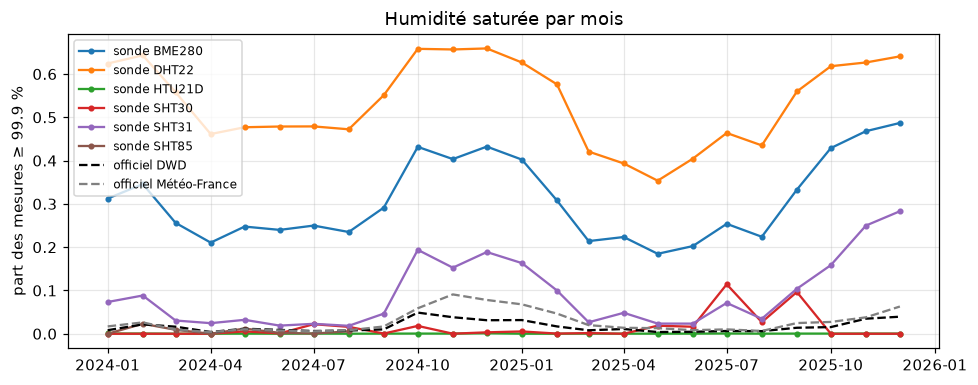

In [15]:
by_month = hum.status_shares(
    hp.with_columns(month=pl.col("timestamp").dt.truncate("1mo")), ["sensor_type", "month"], H
).collect()
official_month = (
    official.with_columns(month=pl.col("time_utc").dt.truncate("1mo"))
    .group_by("source", "month")
    .agg(saturated_share=hum.is_saturated(pl.col("humidity"), SAT).mean())
    .sort("month")
)
fig, ax = plt.subplots(figsize=(9, 3.6))
for (sensor_type,), part in by_month.filter(pl.col("n") > 10_000).group_by(
    "sensor_type", maintain_order=True
):
    if part.height > 2:
        ax.plot(part["month"], part["saturated_share"], marker=".", label=f"sonde {sensor_type}")
for (source,), part in official_month.group_by("source", maintain_order=True):
    ax.plot(
        part["month"],
        part["saturated_share"],
        ls="--",
        color="k" if source == "DWD" else "grey",
        label=f"officiel {source}",
    )
ax.set_ylabel(f"part des mesures ≥ {SAT:g} %")
ax.set_title("Humidité saturée par mois")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "02_humidite_saturee_par_mois.png")

**Ce qu'on fait.** On regarde de plus près les deux défauts inattendus : les valeurs **figées basses** et **hors
bornes**. Quelles valeurs exactes, sur combien de sondes ?

**Pourquoi.** Une valeur répétée des millions de fois à l'identique (1,0 %, 119 %) n'est pas une mesure, c'est la
signature d'un composant bloqué. Il faut savoir si quelques sondes concentrent le problème.

In [16]:
odd = (
    hp.with_columns(status=hum.reading_status(pl.col("humidity"), H))
    .filter(pl.col("status").is_in([hum.STUCK_LOW, hum.OUT_OF_RANGE]))
    .group_by("sensor_type", "status", "humidity")
    .agg(mesures=pl.len(), sondes=pl.col("sensor_id").n_unique())
    .collect()
    .sort("mesures", descending=True)
)
print(
    odd.group_by("sensor_type", "status")
    .agg(mesures=pl.col("mesures").sum())
    .sort("mesures", descending=True)
)
odd.head(8)

shape: (6, 3)
┌─────────────┬──────────────┬──────────┐
│ sensor_type ┆ status       ┆ mesures  │
│ ---         ┆ ---          ┆ ---      │
│ str         ┆ str          ┆ u32      │
╞═════════════╪══════════════╪══════════╡
│ DHT22       ┆ stuck_low    ┆ 11490191 │
│ BME280      ┆ stuck_low    ┆ 944555   │
│ HTU21D      ┆ out_of_range ┆ 659236   │
│ HTU21D      ┆ stuck_low    ┆ 21058    │
│ BME280      ┆ out_of_range ┆ 9757     │
│ DHT22       ┆ out_of_range ┆ 499      │
└─────────────┴──────────────┴──────────┘


sensor_type,status,humidity,mesures,sondes
str,str,f64,u32,u32
"""DHT22""","""stuck_low""",1.0,11220291,166
"""BME280""","""stuck_low""",0.0,937724,63
"""HTU21D""","""out_of_range""",118.99,439785,4
"""HTU21D""","""out_of_range""",-6.0,116409,2
"""DHT22""","""stuck_low""",0.0,24045,7
"""DHT22""","""stuck_low""",1.4,10558,142
"""BME280""","""out_of_range""",-1.0,9561,2
"""DHT22""","""stuck_low""",1.8,7241,139


**Ce qu'on observe.** Deux défauts **figés** que l'échantillon de janvier ne montrait pas : **11,2 millions
de mesures DHT22 valent exactement 1,0 %** (166 sondes, 6,7 % des mesures DHT22), et 0,94 million de mesures
BME280 valent exactement 0 % (63 sondes ; ces lignes ont aussi une température moyenne de −33 °C et une pression de
303 hPa : la puce ne répond plus). Les valeurs hors bornes sont rares mais typiques : HTU21D bloquée à 118,99 % ou
−6 % (les deux bornes de sa formule de conversion, 4 sondes sur 5), BME280 à 255 ou 655,35 (débordement d'entier).
Les 1,93 million de `NaN` des BME280 sont classés manquants : sans ce traitement, ils auraient gonflé la saturation
BME280 de 1,7 point. Sur toutes les mesures, la part **utilisable** n'est que de **39,7 %** pour la DHT22 et
68,6 % pour la BME280, contre 91–99 % pour les sondes Sensirion (SHT30/31/85), rares (21 sondes). La saturation suit
la saison humide : DHT22 66 % en octobre–décembre 2024 contre 35 % en mai 2025, alors que les stations officielles
ne dépassent jamais 9 % (Météo-France, novembre 2024).

### 7.1 Sondes « mortes » ou défauts épisodiques ?

**Ce qu'on fait.** On travaille à l'heure puis au mois, pour chaque sonde :

- une **heure en défaut** = plus de la moitié de ses mesures ne sont pas utilisables (saturées, figées basses ou hors
  bornes ; `humidity.faulty_hour_share`) ; son défaut dominant est noté ;
- pour chaque **mois-sonde**, la part d'heures en défaut :
$$
s_{\text{mois}} = \frac{\text{heures en défaut}}{\text{heures avec au moins une mesure d'humidité}}
$$

On regarde la distribution de $s_{\text{mois}}$ pour choisir un seuil $X$ (`humidity.dead_month_share`) :

- $s_{\text{mois}} > X$ : sonde **morte** ce mois-là → tout le mois est « sans humidité locale fiable », même les
  heures non saturées (une sonde bloquée près de 100 % qui affiche brièvement 97 % ne mérite pas confiance) ;
- $s_{\text{mois}} \le X$ : sonde **saine** avec des défauts **épisodiques** → on écarte seulement ces heures.

La distribution seule ne suffit pas à fixer $X$ : on vérifie aussi, contre la station météo officielle de rang 1, si les
heures **utilisables** d'un mois sont fiables selon $s_{\text{mois}}$. Si elles dérivent quand $s_{\text{mois}}$
augmente, la sonde est en train de mourir et même ses heures « normales » sont suspectes.

**Pourquoi.** Les deux défauts ne se traitent pas pareil : jeter tout le mois d'une sonde saine gaspillerait des
heures utiles ; garder les heures « non saturées » d'une sonde morte ferait entrer des valeurs fausses.

18,744 mois-sondes, 1126 sondes


tranche,mois_sondes,part
str,u32,f64
"""0 %""",4500,0.24
"""0–10 %""",1670,0.089
"""10–30 %""",1458,0.078
"""30–50 %""",1418,0.076
"""50–70 %""",1850,0.099
"""70–90 %""",2643,0.141
"""> 90 %""",5205,0.278


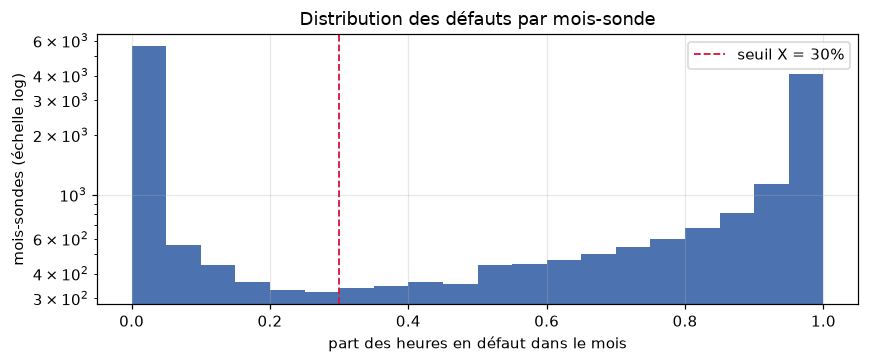

In [17]:
probe_hourly = hum.hourly_humidity(hp, H).collect()
monthly = hum.monthly_quality(probe_hourly).collect()
X = H.dead_month_share
edges = [i / 20 for i in range(21)]
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.hist(monthly["faulty_month_share"], bins=edges, color="#4C72B0")
ax.axvline(X, color="crimson", ls="--", lw=1.2, label=f"seuil X = {X:.0%}")
ax.set_yscale("log")
ax.set_xlabel("part des heures en défaut dans le mois")
ax.set_ylabel("mois-sondes (échelle log)")
ax.set_title("Distribution des défauts par mois-sonde")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "02_saturation_par_mois_sonde.png")
counts = (
    monthly.with_columns(
        tranche=pl.when(pl.col("faulty_month_share") == 0)
        .then(pl.lit("0 %"))
        .when(pl.col("faulty_month_share") <= 0.1)
        .then(pl.lit("0–10 %"))
        .when(pl.col("faulty_month_share") <= 0.3)
        .then(pl.lit("10–30 %"))
        .when(pl.col("faulty_month_share") <= 0.5)
        .then(pl.lit("30–50 %"))
        .when(pl.col("faulty_month_share") <= 0.7)
        .then(pl.lit("50–70 %"))
        .when(pl.col("faulty_month_share") <= 0.9)
        .then(pl.lit("70–90 %"))
        .otherwise(pl.lit("> 90 %"))
    )
    .group_by("tranche")
    .agg(mois_sondes=pl.len())
    .with_columns(part=(pl.col("mois_sondes") / pl.col("mois_sondes").sum()).round(3))
)
print(f"{monthly.height:,} mois-sondes, {monthly['sensor_id'].n_unique()} sondes")
counts.sort("tranche")

In [18]:
link1 = probe_site.join(weather_links.filter(pl.col("rank") == 1), on="sampling_point").unique("sensor_id")
official_hourly = (
    link1.select("sensor_id", "station_id", "source")
    .join(
        official.select("source", "station_id", hour="time_utc", official_humidity="humidity"),
        on=["source", "station_id"],
    )
    .select("sensor_id", "hour", "official_humidity")
    .drop_nulls()
)
both = (
    probe_hourly.join(official_hourly, on=["sensor_id", "hour"], how="inner")
    .with_columns(month=pl.col("hour").dt.truncate("1mo").dt.date())
    .join(monthly.select("sensor_id", "month", "faulty_month_share"), on=["sensor_id", "month"])
)
gap = pl.col("humidity") - pl.col("official_humidity")
agreement = (
    both.filter(~pl.col("faulty"), pl.col("sensor_type").is_in(["DHT22", "BME280"]))
    .with_columns(s_mois=(pl.col("faulty_month_share") * 10).floor().clip(0, 9) / 10)
    .group_by("sensor_type", "s_mois")
    .agg(heures=pl.len(), biais=gap.median().round(1), corr=pl.corr("humidity", "official_humidity").round(2))
    .sort("sensor_type", "s_mois")
)
sensitivity = pl.concat(
    [
        hum.classify_months(monthly, x)
        .select(
            X_candidat=pl.lit(x),
            part_mois_morts=(pl.col("status") == hum.DEAD).mean().round(3),
            heures_récupérables=pl.col("recoverable_hours").sum(),
            part_récupérable=(pl.col("recoverable_hours").sum() / pl.col("hours").sum()).round(3),
        )
        .collect()
        for x in (0.1, 0.2, 0.3, 0.4, 0.5, 0.7)
    ]
)
print(sensitivity)
agreement.pivot(on="sensor_type", index="s_mois", values=["biais", "corr", "heures"])

shape: (6, 4)
┌────────────┬─────────────────┬─────────────────────┬──────────────────┐
│ X_candidat ┆ part_mois_morts ┆ heures_récupérables ┆ part_récupérable │
│ ---        ┆ ---             ┆ ---                 ┆ ---              │
│ f64        ┆ f64             ┆ u32                 ┆ f64              │
╞════════════╪═════════════════╪═════════════════════╪══════════════════╡
│ 0.1        ┆ 0.671           ┆ 3905093             ┆ 0.326            │
│ 0.2        ┆ 0.628           ┆ 4348551             ┆ 0.363            │
│ 0.3        ┆ 0.593           ┆ 4664339             ┆ 0.389            │
│ 0.4        ┆ 0.556           ┆ 4951511             ┆ 0.413            │
│ 0.5        ┆ 0.517           ┆ 5207222             ┆ 0.434            │
│ 0.7        ┆ 0.419           ┆ 5685916             ┆ 0.474            │
└────────────┴─────────────────┴─────────────────────┴──────────────────┘


s_mois,biais_BME280,biais_DHT22,corr_BME280,corr_DHT22,heures_BME280,heures_DHT22
f64,f64,f64,f64,f64,u32,u32
0.0,-13.0,-9.6,0.68,0.52,2074458,1482261
0.1,-2.3,3.6,0.83,0.53,290089,128535
0.2,1.0,8.8,0.82,0.41,184481,113943
0.3,2.7,13.8,0.79,0.38,151593,116910
0.4,3.6,16.8,0.77,0.39,104885,134305
0.5,5.7,21.9,0.74,0.26,108192,147729
0.6,8.0,25.9,0.68,0.23,66601,144893
0.7,12.2,26.7,0.56,-0.05,49235,128875
0.8,15.3,27.1,0.56,-0.17,36874,98432


**Ce qu'on observe.** Sur le volume complet, la distribution de $s_{\text{mois}}$ n'est **pas** nettement
bimodale (contrairement à l'échantillon d'un mois) : 24 % des mois-sondes n'ont aucune heure en défaut, 27,8 % en
ont plus de 90 %, et entre les deux la densité est la plus faible de **10 à 50 %** (≈ 3,5–3,8 % des mois-sondes par
tranche de 10 points). Le tableau de concordance avec la station officielle tranche : dans les mois où
$0 < s_{\text{mois}} < 0{,}3$, les heures utilisables suivent l'humidité officielle (BME280 : biais médian −2,3 à
+1,0 point, corrélation 0,82–0,83 ; DHT22 : +3,6 à +8,8 points) ; à partir de 0,3 le biais grimpe régulièrement
(DHT22 +13,8 points dans la tranche 0,3–0,4, +21,9 dans 0,5–0,6 ; BME280 +2,7 puis +5,7) et la corrélation DHT22
tombe sous 0,4 : la sonde se mouille et **même ses heures non saturées sont fausses**. On retient **X = 0,3** (`humidity.dead_month_share`) : dans le creux de la distribution,
au point où la dérive devient nette. Le coût est chiffré : 38,9 % des heures récupérables contre 43,4 % avec X =
0,5, soit 0,54 million d'heures de sonde sacrifiées pour ne garder que des valeurs crédibles. Remarque
inattendue : les mois **sans aucun défaut** lisent trop **sec** (biais médian −13 points BME280, −9,6 DHT22) :
sonde chauffée par l'électronique du boîtier. L'humidité locale « fiable » n'est donc pas « juste » : l'étape 5
devra la corriger ou la combiner avec l'humidité officielle.

In [19]:
classified = hum.classify_months(monthly, X).collect()
status = hum.probe_status(classified).collect()
print("sondes par classe :")
print(
    status.group_by("sensor_type", "probe_class")
    .agg(sondes=pl.len())
    .pivot(on="probe_class", index="sensor_type", values="sondes")
    .fill_null(0)
    .sort("sensor_type")
)
hours = classified.select(
    heures_avec_mesure=pl.col("hours").sum(),
    perdues_mois_morts=pl.when(pl.col("status") == hum.DEAD).then(pl.col("hours")).otherwise(0).sum(),
    écartées_épisodiques=pl.when(pl.col("status") == hum.HEALTHY)
    .then(pl.col("faulty_hours"))
    .otherwise(0)
    .sum(),
    récupérables=pl.col("recoverable_hours").sum(),
)
print(hours.with_columns(part_récupérable=(pl.col("récupérables") / pl.col("heures_avec_mesure")).round(3)))
status.group_by("sensor_type", "probe_class").agg(
    sondes=pl.len(), heures=pl.col("hours").sum(), récupérables=pl.col("recoverable_hours").sum()
).with_columns(part_récupérable=(pl.col("récupérables") / pl.col("heures")).round(3)).sort(
    "sensor_type", "probe_class"
)

sondes par classe :
shape: (6, 4)
┌─────────────┬─────────────────────┬───────┬────────────────────────┐
│ sensor_type ┆ morte certains mois ┆ saine ┆ morte toute la période │
│ ---         ┆ ---                 ┆ ---   ┆ ---                    │
│ str         ┆ u32                 ┆ u32   ┆ u32                    │
╞═════════════╪═════════════════════╪═══════╪════════════════════════╡
│ BME280      ┆ 230                 ┆ 150   ┆ 93                     │
│ DHT22       ┆ 141                 ┆ 118   ┆ 368                    │
│ HTU21D      ┆ 2                   ┆ 1     ┆ 2                      │
│ SHT30       ┆ 1                   ┆ 3     ┆ 0                      │
│ SHT31       ┆ 5                   ┆ 11    ┆ 0                      │
│ SHT85       ┆ 0                   ┆ 1     ┆ 0                      │
└─────────────┴─────────────────────┴───────┴────────────────────────┘
shape: (1, 5)
┌────────────────────┬────────────────────┬──────────────────────┬──────────────┬──────────────────┐

sensor_type,probe_class,sondes,heures,récupérables,part_récupérable
str,str,u32,u32,u32,f64
"""BME280""","""morte certains mois""",230,2586849,1380325,0.534
"""BME280""","""morte toute la période""",93,835549,0,0.0
"""BME280""","""saine""",150,1264301,1250568,0.989
"""DHT22""","""morte certains mois""",141,1710034,560122,0.328
"""DHT22""","""morte toute la période""",368,4046319,0,0.0
"""DHT22""","""saine""",118,1246040,1236931,0.993
"""HTU21D""","""morte certains mois""",2,20815,7212,0.346
"""HTU21D""","""morte toute la période""",2,21426,0,0.0
"""HTU21D""","""saine""",1,14285,14285,1.0


### 7.2 L'âge de la sonde

**Ce qu'on fait.** Pour chaque mois-sonde, on calcule l'âge de la sonde à ce mois (date d'enregistrement estimée, voir
ci-dessus) et on croise avec le statut : part des mois « morts », et, pour les mois sains, part des heures saturées.

**Pourquoi.** Si les sondes meurent en vieillissant, une variable « âge » aidera le modèle, et un capteur ancien sans
historique d'humidité fiable sera à traiter avec prudence.

sondes sans date d'enregistrement : 0


sensor_type,age,sondes,mois_sondes,part_mois_morts,défaut_épisodique,heures_récupérables
str,str,u32,u32,f64,f64,u32
"""BME280""","""<1""",169,1206,0.193,0.03,582352
"""BME280""","""1-2""",127,895,0.398,0.047,334765
"""BME280""","""2-4""",183,1645,0.486,0.058,520495
"""BME280""","""4-6""",222,2304,0.45,0.056,789918
"""BME280""",""">=6""",113,1320,0.492,0.063,403363
"""DHT22""","""<1""",45,345,0.501,0.017,92431
"""DHT22""","""1-2""",54,343,0.472,0.035,108564
"""DHT22""","""2-4""",165,1096,0.583,0.03,286285
"""DHT22""","""4-6""",426,4145,0.75,0.037,638517


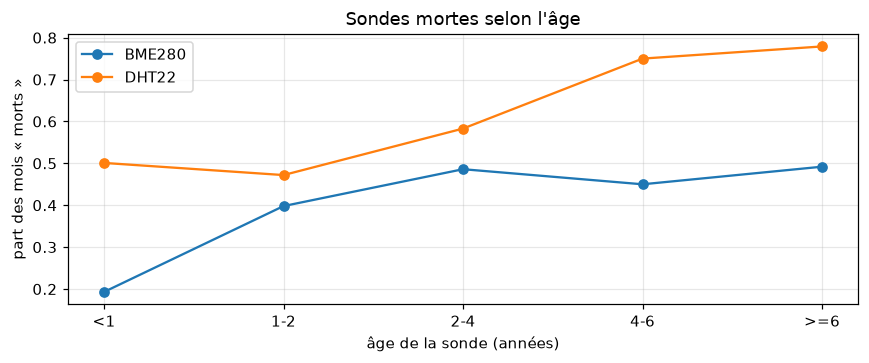

In [20]:
registrations = pl.read_parquet(REF / "sensor_registrations.parquet")
aged = (
    classified.join(registrations, on="sensor_id", how="left")
    .with_columns(age_years=(pl.col("month") - pl.col("registered_by")).dt.total_days() / 365.25)
    .with_columns(
        age=hum.age_class(pl.col("age_years").clip(lower_bound=0), settings.humidity.age_breaks_years)
    )
)
print(
    "sondes sans date d'enregistrement :",
    aged.filter(pl.col("registered_by").is_null())["sensor_id"].n_unique(),
)
by_age = (
    aged.filter(pl.col("age").is_not_null())
    .group_by("sensor_type", "age")
    .agg(
        sondes=pl.col("sensor_id").n_unique(),
        mois_sondes=pl.len(),
        part_mois_morts=(pl.col("status") == hum.DEAD).mean().round(3),
        défaut_épisodique=(
            pl.when(pl.col("status") == hum.HEALTHY).then(pl.col("faulty_hours")).sum()
            / pl.when(pl.col("status") == hum.HEALTHY).then(pl.col("hours")).sum()
        ).round(3),
        heures_récupérables=pl.col("recoverable_hours").sum(),
    )
    .filter(pl.col("sondes") >= 5)
    .sort("sensor_type", pl.col("age").cast(pl.Enum(["<1", "1-2", "2-4", "4-6", ">=6"])))
)
fig, ax = plt.subplots(figsize=(8, 3.4))
for (sensor_type,), part in by_age.group_by("sensor_type", maintain_order=True):
    if part.height >= 3:
        ax.plot(part["age"], part["part_mois_morts"], marker="o", label=sensor_type)
ax.set_xlabel("âge de la sonde (années)")
ax.set_ylabel("part des mois « morts »")
ax.set_title("Sondes mortes selon l'âge")
if ax.lines:
    ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "02_sondes_mortes_par_age.png")
by_age

**Ce qu'on observe.** Répartition des 1 126 sondes ayant des mesures, avec X = 0,3 : **DHT22** 118 saines,
141 mortes certains mois, **368 mortes toute la période (59 %)** ; **BME280** 150 saines, 230 mortes certains mois,
93 mortes toute la période (20 %) ; Sensirion (SHT3x/85) 15 saines sur 21, aucune morte toute la période. Heures :
11,99 millions d'heures-sondes avec une mesure, **7,10 M perdues** dans les mois morts, 0,22 M écartées comme
défauts épisodiques dans les mois sains, **4,66 M récupérables (38,9 %)**. Une sonde saine rend 99 % de ses heures ;
une sonde « morte certains mois » 53 % (BME280) ou 33 % (DHT22). **L'âge compte** : la part de mois morts passe,
pour la DHT22, de 47–50 % la première année à **75–78 % après 4 ans** ; pour la BME280, de **19 %** la première
année à 40–49 % ensuite. La saturation épisodique des mois sains augmente aussi avec l'âge (BME280 3,0 % → 6,3 %).
Un capteur DHT22 de plus de 4 ans n'a, en pratique, presque plus d'humidité locale : l'âge (estimé par
l'identifiant, toutes les sondes ont une date) sera une variable utile, et l'humidité officielle sera la règle
plutôt que l'exception.

### 7.3 La preuve : sonde saturée contre station officielle à la même heure

**Ce qu'on fait.** Pour chaque heure, on compare l'humidité moyenne **affichée** par la sonde (défauts compris, hors
valeurs impossibles) à celle de la station météo officielle de rang 1 de sa paire, **à la même heure UTC**. À gauche,
toutes les heures (densité en 2D) ; à droite, seulement les heures où la sonde est en défaut « saturée ».

**Pourquoi.** Si la saturation était de l'air vraiment saturé (brouillard), la station officielle serait elle aussi
à ≈ 100 % ces heures-là. Si elle mesure 60–90 %, c'est la **sonde** qui est en défaut.

heures comparables : 11,541,848 | dont sonde en défaut « saturée » : 5,110,873
quand la sonde est saturée, la station officielle l'est aussi : 2.1%
… elle mesure moins de 90 % : 63.3% | moins de 80 % : 35.1%
médiane de l'humidité officielle quand la sonde est saturée : 85 %


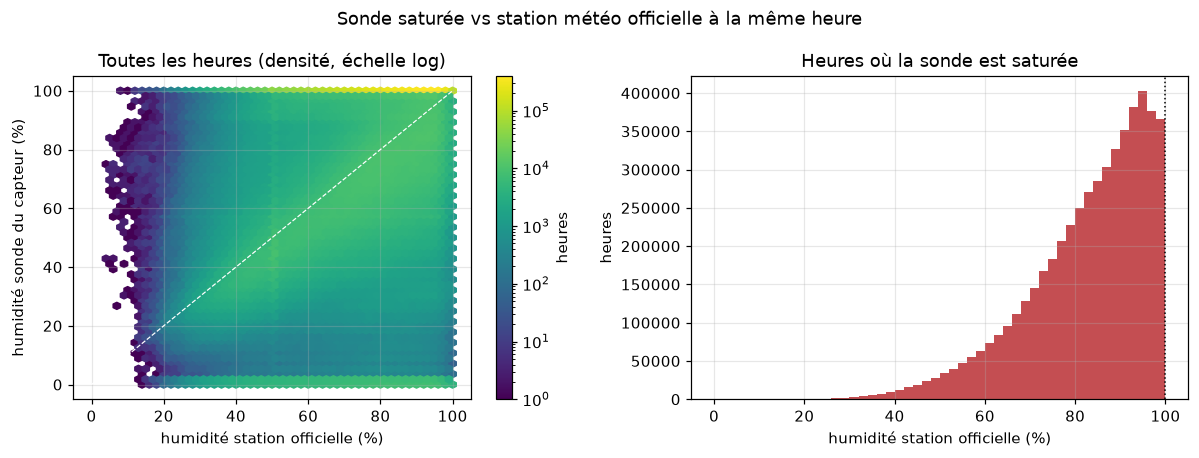

In [21]:
ghost = hum.saturated_vs_official(probe_hourly, official_hourly, SAT)
print(f"heures comparables : {both.height:,} | dont sonde en défaut « saturée » : {ghost.height:,}")
official_rh = ghost["official_humidity"]
also_saturated = ghost["official_saturated"].mean()
print(f"quand la sonde est saturée, la station officielle l'est aussi : {also_saturated:.1%}")
below90, below80 = (official_rh < 90).mean(), (official_rh < 80).mean()
print(f"… elle mesure moins de 90 % : {below90:.1%} | moins de 80 % : {below80:.1%}")
print(f"médiane de l'humidité officielle quand la sonde est saturée : {official_rh.median():.0f} %")
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
claimed = both.drop_nulls("raw_humidity")
hb = axes[0].hexbin(
    claimed["official_humidity"],
    claimed["raw_humidity"],
    gridsize=50,
    bins="log",
    cmap="viridis",
    extent=(0, 100, 0, 100),
)
axes[0].plot([0, 100], [0, 100], color="w", lw=0.8, ls="--")
axes[0].set_xlabel("humidité station officielle (%)")
axes[0].set_ylabel("humidité sonde du capteur (%)")
axes[0].set_title("Toutes les heures (densité, échelle log)")
fig.colorbar(hb, ax=axes[0], label="heures")
axes[1].hist(ghost["official_humidity"], bins=50, range=(0, 100), color="#C44E52")
axes[1].axvline(SAT, color="k", ls=":", lw=1)
axes[1].set_xlabel("humidité station officielle (%)")
axes[1].set_ylabel("heures")
axes[1].set_title("Heures où la sonde est saturée")
fig.suptitle("Sonde saturée vs station météo officielle à la même heure")
fig.tight_layout()
fig.savefig(FIG_DIR / "02_saturation_vs_officiel.png")

**Ce qu'on observe.** **C'est la preuve demandée.** Sur 11,5 millions d'heures comparables, 5,11 millions
sont des heures où la sonde est saturée. Pendant ces heures, la station officielle voisine n'est saturée que
**2,1 %** du temps ; elle mesure **moins de 90 % dans 63 %** des cas et moins de 80 % dans 35 % ; sa médiane est
**85 %**. À gauche, la bande jaune horizontale à 100 % (et celle à ≈ 0–1 %) couvre toutes les humidités
officielles de 20 à 100 % : la sonde affiche 100 % (ou 1 %) quel que soit l'air réel. Ce n'est pas du brouillard,
c'est une **panne de sonde** : la règle « saturée ou figée = manquante » est justifiée. Un air humide (85 % en
médiane) est bien le déclencheur : les sondes se mouillent quand il fait humide, puis ne sèchent plus.

## 8. Des capteurs qui changent de place

**Ce qu'on fait.** Chaque ligne brute porte le site (`location`) et les coordonnées. On liste, pour chaque capteur PM,
les positions distinctes rencontrées pendant la période et la distance entre la première et la dernière.

**Pourquoi.** La distance capteur ↔ station a été calculée à partir de la position la plus récente. Un capteur
déménagé pendant la période a, avant son déménagement, une autre distance (voire une autre station la plus proche) :
l'étape 3 devra découper ses mesures par position.

In [22]:
positions = position_history(pm.select("sensor_id", "location", "lat", "lon", "timestamp")).collect()
moved = (
    positions.group_by("sensor_id")
    .agg(
        positions=pl.len(),
        sites=pl.col("location").n_unique(),
        lat0=pl.col("lat").first(),
        lon0=pl.col("lon").first(),
        lat1=pl.col("lat").last(),
        lon1=pl.col("lon").last(),
    )
    .filter(pl.col("positions") > 1)
    .with_columns(
        déplacement_km=haversine_km(pl.col("lat0"), pl.col("lon0"), pl.col("lat1"), pl.col("lon1")).round(2)
    )
)
print(f"capteurs PM avec plus d'une position : {moved.height} sur {positions['sensor_id'].n_unique()}")
moved.select("sensor_id", "positions", "sites", "déplacement_km").sort(
    "déplacement_km", descending=True
).head(10)

capteurs PM avec plus d'une position : 65 sur 1399


sensor_id,positions,sites,déplacement_km
i64,u32,u32,f64
84804,2,2,8452.76
36947,2,2,2386.67
10569,2,2,627.35
87524,4,3,370.22
86868,3,3,366.22
42694,3,2,177.17
9232,2,2,153.45
52206,2,2,114.84
68184,2,2,63.15


**Ce qu'on observe.** 65 capteurs PM sur 1 399 ont plus d'une position dans la période : 23 d'entre eux ont
bougé de moins de 100 m (coordonnées arrondies ou corrigées ; 12 capteurs ont changé de coordonnées sans changer de site), 21 de 0,1 à 3 km, et
**21 de plus de 3 km**, donc hors de portée de leur station pendant une partie de la période. Cas extrêmes : le
capteur 84804 était **à Hanoï** (21,06° N ; 105,83° E) jusqu'au 5 septembre 2025 avant d'arriver à Magdebourg ; le
36947 a eu pendant 11 heures une position en Russie, près de Samara (erreur de saisie probable). Comme la distance et la
station ont été calculées sur la position la plus récente, l'étape 3 découpera les mesures par position et ne
gardera que celles où le capteur est réellement à portée de sa station.

## 9. Bilan de l'étape 2

- **Volumes réels** : 45 337 unités capteur × mois, 1,21 million de fichiers reçus (5,85 Go), 667,7 millions de
  lignes en bronze ; EEA 582 points, DWD 222 stations, Météo-France 85 stations. **0 échec** sur toutes les sources.
- **Durée** : 3 h 04 de téléchargement (dont 3,05 h pour Sensor.Community), 12 min 35 s de conversion.
- **Disque** : pic ≈ 11 Go, état final 5,9 Go (bronze 5,0 Go).
- **Contrat** : aucune ligne rejetée ; un défaut de notre lecture (virgule décimale) corrigé et rejoué.
- **Humidité, le risque n°1, est confirmée** : seules **39 % des heures-sondes** sont récupérables (X = 0,3), 59 %
  des DHT22 sont mortes toute la période, la mort augmente avec l'âge, et la comparaison aux stations officielles
  prouve que la saturation est une panne (station officielle saturée 2,1 % du temps seulement). Toutes les paires
  ont une station météo officielle de secours (médiane 6,4 km du capteur), à l'horloge UTC vérifiée.
- **Pour l'étape 3 (silver)** : statut de chaque mesure d'humidité (`reading_status`), mois morts et heures en
  défaut → manquants, drapeau « humidité locale fiable », humidité officielle de rang 1 puis 2 ; sentinelles −999
  (EEA, DWD) → manquant ; `NaN` → manquant ; découpage des capteurs déplacés ; normalisation de `sensor_type` ;
  contrôle d'horloge sur toutes les paires.